In [3]:
import seaborn as sns
import yfinance as yf
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor

In [6]:
import yfinance as yf

btc = yf.Ticker('BTC-USD')
prices1 = btc.history(period='5y')
prices1 = prices1[['Close', 'Volume']].copy()

eth = yf.Ticker('ETH-USD')
prices2 = eth.history(period='5y')
prices2 = prices2[['Close', 'Volume']].copy()

usdt = yf.Ticker('USDT-USD')
prices3 = usdt.history(period='5y')
prices3 = prices3[['Close', 'Volume']].copy()

bnb = yf.Ticker('BNB-USD')
prices4 = bnb.history(period='5y')
prices4 = prices4[['Close', 'Volume']].copy()

print(prices1.head())

                                  Close       Volume
Date                                                
2021-10-08 00:00:00+00:00  53967.847656  34800873924
2021-10-09 00:00:00+00:00  54968.222656  32491211414
2021-10-10 00:00:00+00:00  54771.578125  39527792364
2021-10-11 00:00:00+00:00  57484.789062  42637331698
2021-10-12 00:00:00+00:00  56041.058594  41083758949


In [7]:
p1 = prices1.join(prices2, lsuffix=' (BTC)', rsuffix=' (ETH)')
p2 = prices3.join(prices4, lsuffix=' (USDT)', rsuffix=' (BNB)')
data = p1.join(p2)

print(data.head())

                            Close (BTC)  Volume (BTC)  Close (ETH)  \
Date                                                                 
2021-10-08 00:00:00+00:00  53967.847656   34800873924  3563.759277   
2021-10-09 00:00:00+00:00  54968.222656   32491211414  3575.716797   
2021-10-10 00:00:00+00:00  54771.578125   39527792364  3425.852783   
2021-10-11 00:00:00+00:00  57484.789062   42637331698  3545.354004   
2021-10-12 00:00:00+00:00  56041.058594   41083758949  3492.573242   

                           Volume (ETH)  Close (USDT)  Volume (USDT)  \
Date                                                                   
2021-10-08 00:00:00+00:00   16222029488      1.000116    79865522045   
2021-10-09 00:00:00+00:00   12707036942      1.000046    67391135102   
2021-10-10 00:00:00+00:00   16171746693      1.001018    69927661418   
2021-10-11 00:00:00+00:00   18579189588      1.000696    75741431317   
2021-10-12 00:00:00+00:00   18109578443      1.000096    73275476508   

    

In [9]:
data.tail()


,Close (BTC),Volume (BTC),Close (ETH),Volume (ETH),Close (USDT),Volume (USDT),Close (BNB),Volume (BNB)
Date,,,,,,,,
2026-10-04 00:00:00+00:00,86480.304688,15031650242,2726.509033,5943841130,0.999790,38186771396,795.264099,1195825218
2026-10-05 00:00:00+00:00,85786.593750,30242651384,2711.031494,12303844539,0.999853,71514114557,786.810486,1629945521
2026-10-06 00:00:00+00:00,85557.562500,25245965925,2697.516357,10986122667,0.999845,60953147088,779.615967,1273219160
2026-10-07 00:00:00+00:00,83275.929688,38737709051,2573.527344,20082324906,0.999445,88736239765,772.301270,1545007708
2026-10-08 00:00:00+00:00,80941.250000,41290637312,2418.159912,18232395776,0.999290,91534082048,725.039978,1632919680


In [8]:
data.head()

,Close (BTC),Volume (BTC),Close (ETH),Volume (ETH),Close (USDT),Volume (USDT),Close (BNB),Volume (BNB)
Date,,,,,,,,
2021-10-08 00:00:00+00:00,53967.847656,34800873924,3563.759277,16222029488,1.000116,79865522045,419.102051,2678048368
2021-10-09 00:00:00+00:00,54968.222656,32491211414,3575.716797,12707036942,1.000046,67391135102,421.549469,1404867667
2021-10-10 00:00:00+00:00,54771.578125,39527792364,3425.852783,16171746693,1.001018,69927661418,405.069305,1437068558
2021-10-11 00:00:00+00:00,57484.789062,42637331698,3545.354004,18579189588,1.000696,75741431317,413.456207,1473121389
2021-10-12 00:00:00+00:00,56041.058594,41083758949,3492.573242,18109578443,1.000096,73275476508,443.867523,3142304145


In [11]:
data.shape

(1827, 8)

In [12]:
data.info()

<class 'pandas.DataFrame'>
DatetimeIndex: 1827 entries, 2021-10-08 00:00:00+00:00 to 2026-10-08 00:00:00+00:00
Data columns (total 8 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Close (BTC)    1827 non-null   float64
 1   Volume (BTC)   1827 non-null   int64  
 2   Close (ETH)    1827 non-null   float64
 3   Volume (ETH)   1827 non-null   int64  
 4   Close (USDT)   1827 non-null   float64
 5   Volume (USDT)  1827 non-null   int64  
 6   Close (BNB)    1827 non-null   float64
 7   Volume (BNB)   1827 non-null   int64  
dtypes: float64(4), int64(4)
memory usage: 128.5 KB


In [13]:
data.isna().sum()

Close (BTC)      0
Volume (BTC)     0
Close (ETH)      0
Volume (ETH)     0
Close (USDT)     0
Volume (USDT)    0
Close (BNB)      0
Volume (BNB)     0
dtype: int64

In [14]:
data.describe()

,Close (BTC),Volume (BTC),Close (ETH),Volume (ETH),Close (USDT),Volume (USDT),Close (BNB),Volume (BNB)
count,1827.000000,1.827000e+03,1827.000000,1.827000e+03,1827.000000,1.827000e+03,1827.000000,1.827000e+03
mean,58831.072206,3.468032e+10,2512.490613,1.760108e+10,0.999977,6.772572e+10,509.473118,1.631524e+09
std,29826.378513,2.056985e+10,881.707070,1.183274e+10,0.000659,4.222412e+10,219.104460,1.091425e+09
min,15787.284180,5.331173e+09,993.636780,2.081626e+09,0.995872,9.989859e+09,197.042999,2.038465e+08
25%,29412.204102,2.041515e+10,1810.192871,9.461958e+09,0.999680,3.933162e+10,304.748932,9.030619e+08
50%,60811.277344,3.020000e+10,2372.201904,1.503225e+10,1.000063,5.811751e+10,553.467407,1.521708e+09
75%,81933.613281,4.260274e+10,3134.237549,2.171727e+10,1.000284,8.340095e+10,638.631531,2.019107e+09
max,124752.531250,1.817464e+11,4831.348633,9.773662e+10,1.007690,3.443980e+11,1310.214355,1.182039e+10


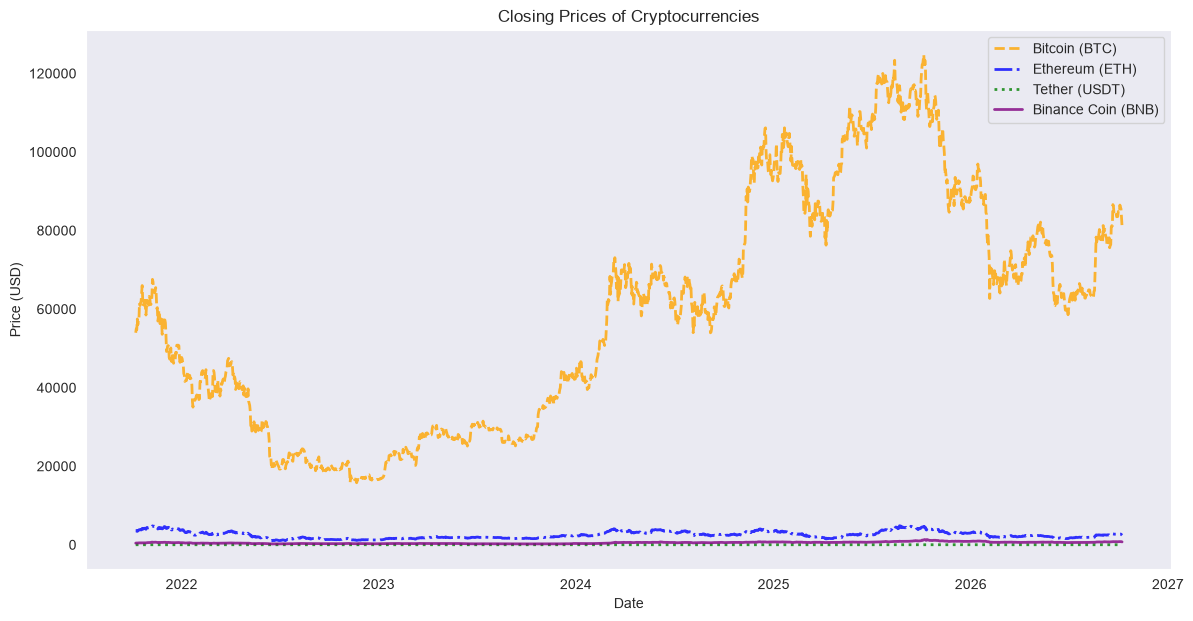

In [20]:
plt.figure(figsize=(14, 7))
plt.plot(data.index, data['Close (BTC)'], label='Bitcoin (BTC)', color='orange', linewidth=2, alpha=0.8, linestyle='--')
plt.plot(data.index, data['Close (ETH)'], label='Ethereum (ETH)', color='blue', linewidth=2, alpha=0.8, linestyle='-.')
plt.plot(data.index, data['Close (USDT)'], label='Tether (USDT)', color='green', linewidth=2, alpha=0.8, linestyle=':')
plt.plot(data.index, data['Close (BNB)'], label='Binance Coin (BNB)', color='purple', linewidth=2, alpha=0.8, linestyle='-')
plt.title('Closing Prices of Cryptocurrencies')
plt.xlabel('Date')
plt.ylabel('Price (USD)')
plt.legend()
plt.show()


C:\Users\karti\AppData\Local\Temp\ipykernel_14868\39109887.py:3: UserWarning: 
The palette list has fewer values (4) than needed (8) and will cycle, which may produce an uninterpretable plot.
  sns.lineplot(data=data, palette=['orange', 'blue', 'green', 'purple'], linewidth=2.5, alpha=0.8)


<Axes: xlabel='Date'>

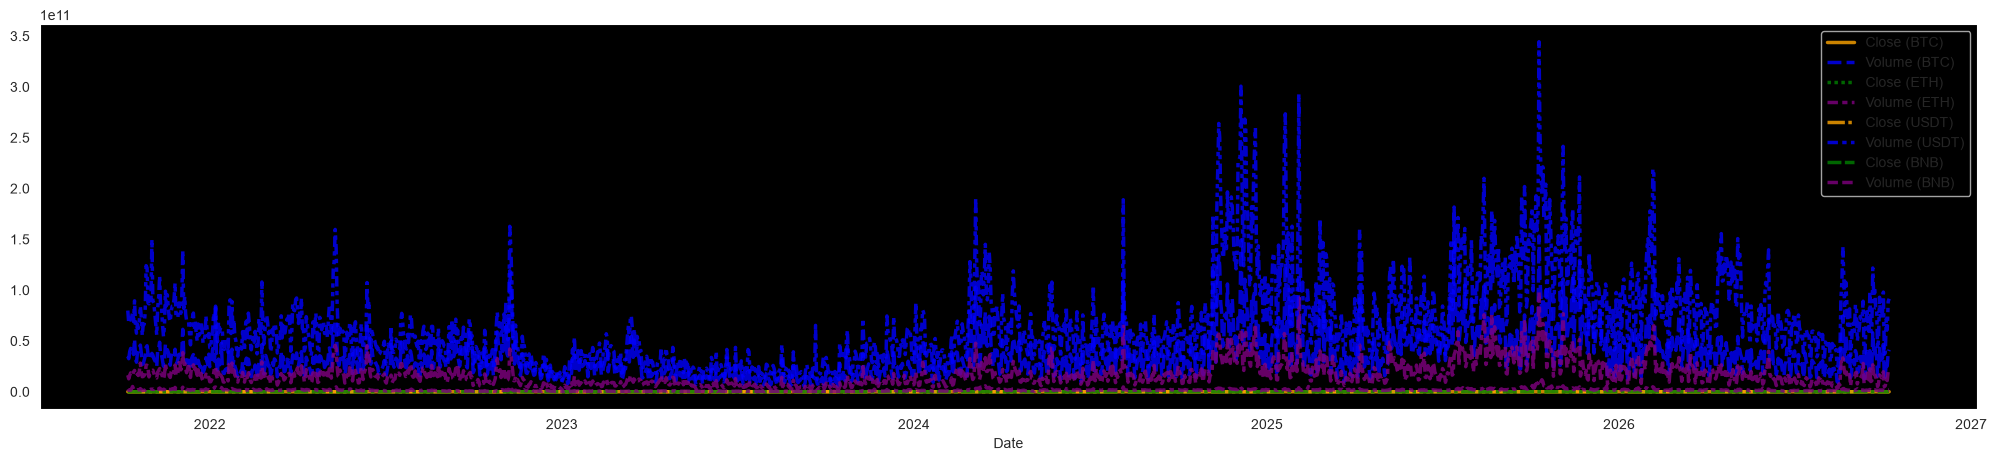

In [24]:
plt.figure(figsize = (25, 5))
sns.set_style('dark', {'axes.facecolor': 'black', 'grid.color': 'gray'})
sns.lineplot(data=data, palette=['orange', 'blue', 'green', 'purple'], linewidth=2.5, alpha=0.8)

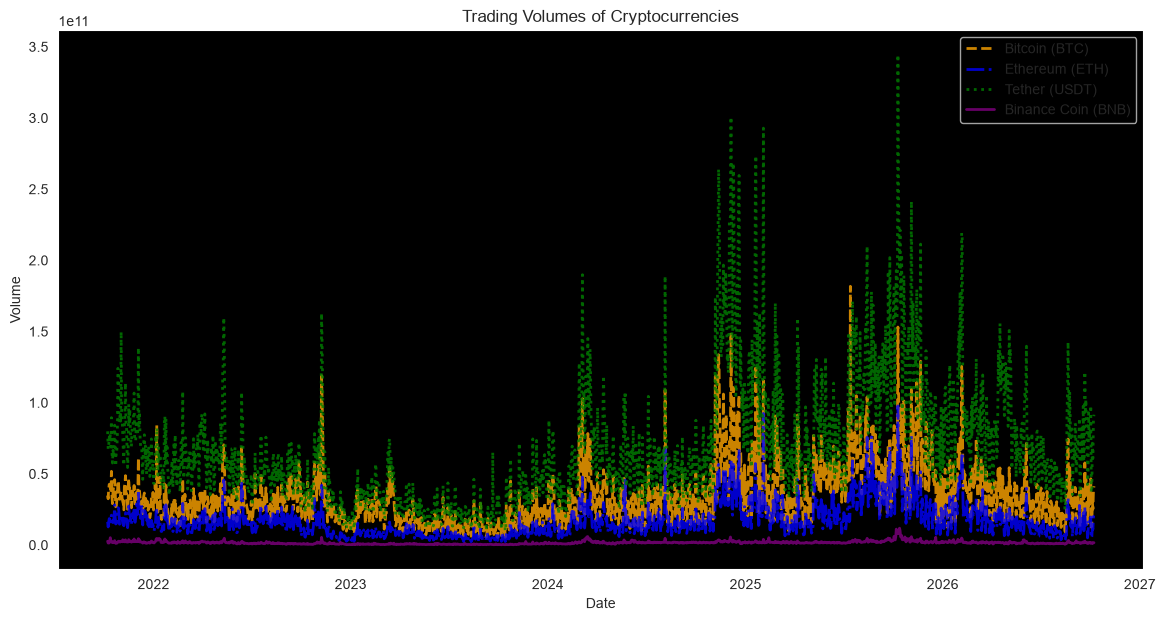

In [25]:
plt.figure(figsize=(14, 7))
plt.plot(data.index, data['Volume (BTC)'], label='Bitcoin (BTC)', color='orange', linewidth=2, alpha=0.8, linestyle='--')
plt.plot(data.index, data['Volume (ETH)'], label='Ethereum (ETH)', color='blue', linewidth=2, alpha=0.8, linestyle='-.')
plt.plot(data.index, data['Volume (USDT)'], label='Tether (USDT)', color='green', linewidth=2, alpha=0.8, linestyle=':')
plt.plot(data.index, data['Volume (BNB)'], label='Binance Coin (BNB)', color='purple', linewidth=2, alpha=0.8, linestyle='-')
plt.title('Trading Volumes of Cryptocurrencies')
plt.xlabel('Date')
plt.ylabel('Volume')
plt.legend()
plt.show()

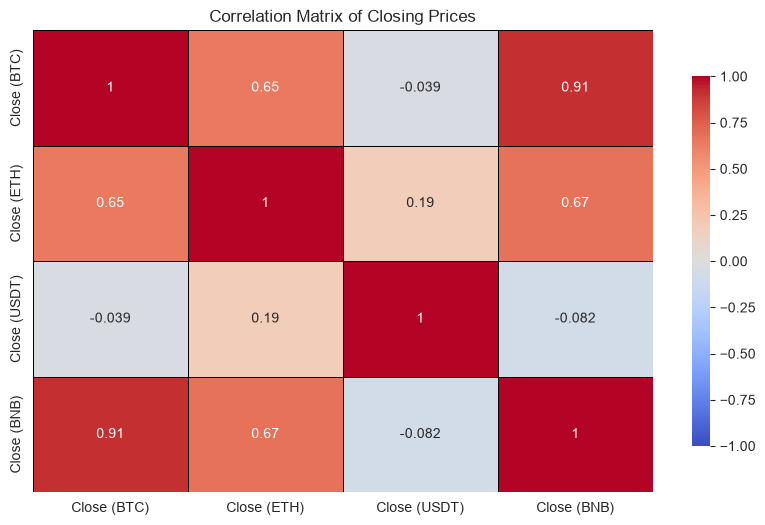

In [26]:
corr_matrix = data[['Close (BTC)', 'Close (ETH)', 'Close (USDT)', 'Close (BNB)']].corr()

# Plot the heatmap
plt.figure(figsize=(10, 6))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', vmin=-1, vmax=1, linewidths=0.5, linecolor='black', cbar_kws={"shrink": 0.8})
plt.title('Correlation Matrix of Closing Prices')
plt.show()

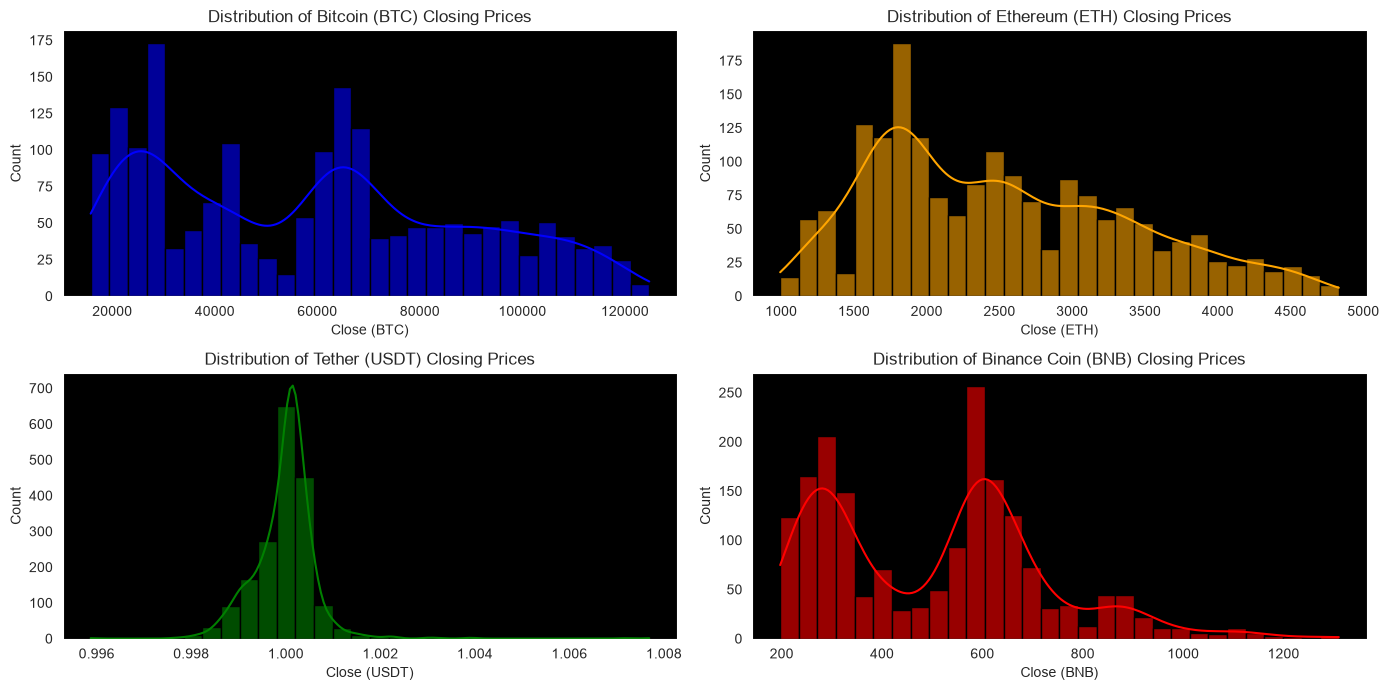

In [30]:
plt.figure(figsize=(14, 7))

plt.subplot(2, 2, 1)
sns.histplot(data['Close (BTC)'], kde=True, color='blue', alpha=0.6, edgecolor='black', bins=30, label='BTC')
plt.title('Distribution of Bitcoin (BTC) Closing Prices')

plt.subplot(2, 2, 2)
sns.histplot(data['Close (ETH)'], kde=True, color='orange', alpha=0.6, edgecolor='black', bins=30, label='ETH')
plt.title('Distribution of Ethereum (ETH) Closing Prices')

plt.subplot(2, 2, 3)
sns.histplot(data['Close (USDT)'], kde=True, color='green', alpha=0.6, edgecolor='black', bins=30, label='USDT')
plt.title('Distribution of Tether (USDT) Closing Prices')

plt.subplot(2, 2, 4)
sns.histplot(data['Close (BNB)'], kde=True, color='red', alpha=0.6, edgecolor='black', bins=30, label='BNB')
plt.title('Distribution of Binance Coin (BNB) Closing Prices')

plt.tight_layout()
plt.show()

array([[<Axes: title={'center': 'Close (BTC)'}>,
        <Axes: title={'center': 'Volume (BTC)'}>,
        <Axes: title={'center': 'Close (ETH)'}>,
        <Axes: title={'center': 'Volume (ETH)'}>],
       [<Axes: title={'center': 'Close (USDT)'}>,
        <Axes: title={'center': 'Volume (USDT)'}>,
        <Axes: title={'center': 'Close (BNB)'}>,
        <Axes: title={'center': 'Volume (BNB)'}>]], dtype=object)

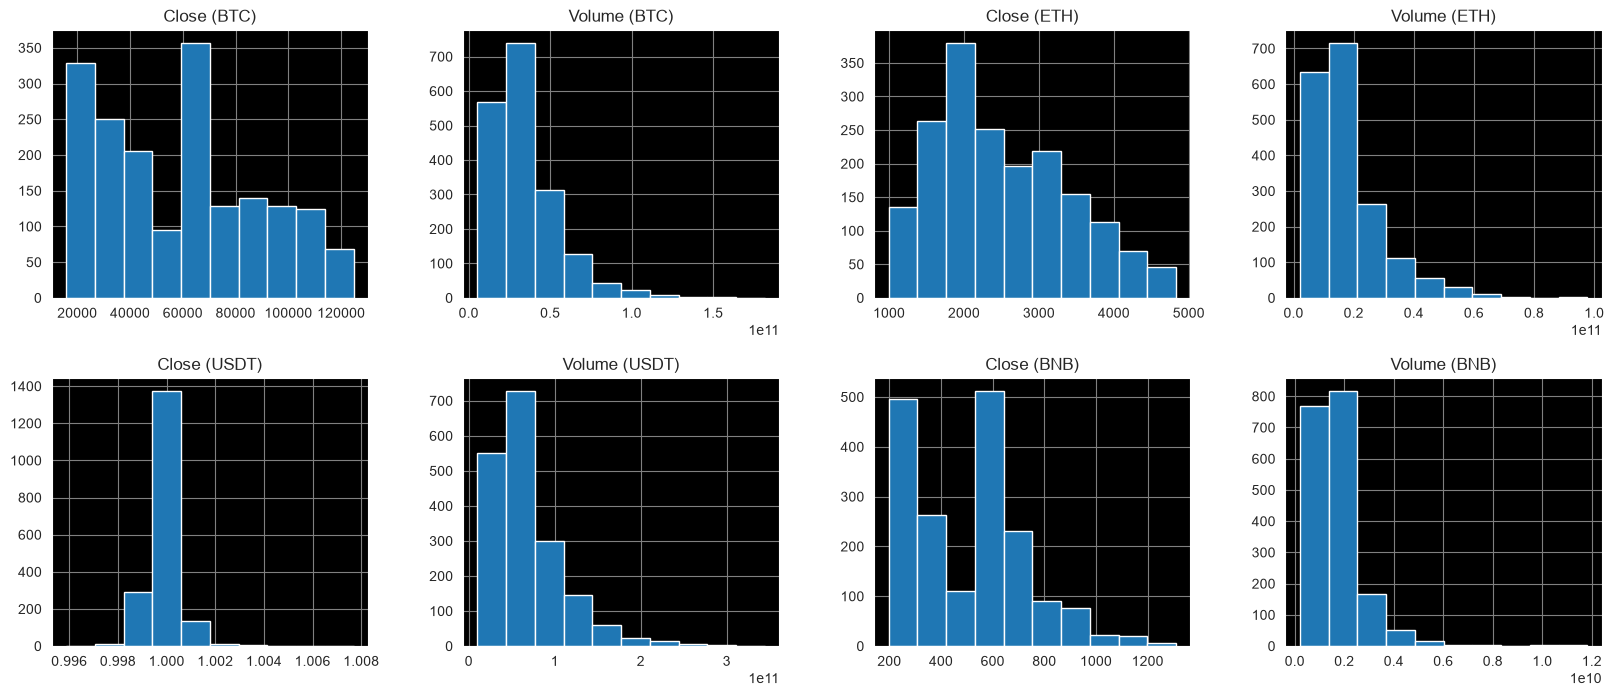

In [33]:
data.hist(figsize=(20, 8), layout=(2, 4))

array([[<Axes: ylabel='Density'>, <Axes: ylabel='Density'>,
        <Axes: ylabel='Density'>, <Axes: ylabel='Density'>],
       [<Axes: ylabel='Density'>, <Axes: ylabel='Density'>,
        <Axes: ylabel='Density'>, <Axes: ylabel='Density'>]], dtype=object)

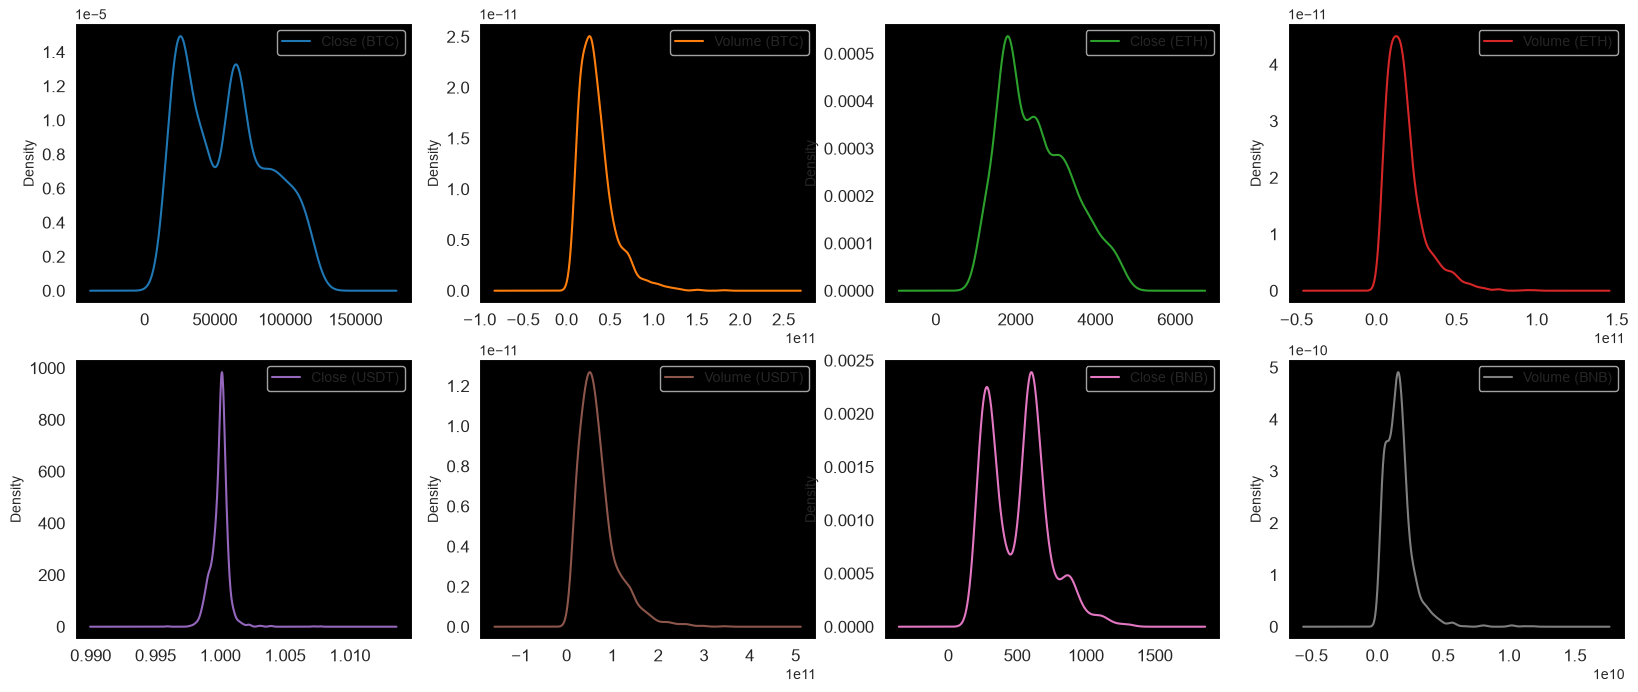

In [35]:
data.plot(kind = "kde", subplots = True, layout = (2, 4), figsize = (20, 8), sharex = False, sharey = False, legend = True, fontsize = 12)

d:\my_python\myenv\Lib\site-packages\seaborn\axisgrid.py:1513: FutureWarning: 

`shade` is now deprecated in favor of `fill`; setting `fill=True`.
This will become an error in seaborn v0.14.0; please update your code.

  func(x=vector, **plot_kwargs)
d:\my_python\myenv\Lib\site-packages\seaborn\axisgrid.py:1513: FutureWarning: 

`shade` is now deprecated in favor of `fill`; setting `fill=True`.
This will become an error in seaborn v0.14.0; please update your code.

  func(x=vector, **plot_kwargs)
d:\my_python\myenv\Lib\site-packages\seaborn\axisgrid.py:1513: FutureWarning: 

`shade` is now deprecated in favor of `fill`; setting `fill=True`.
This will become an error in seaborn v0.14.0; please update your code.

  func(x=vector, **plot_kwargs)
d:\my_python\myenv\Lib\site-packages\seaborn\axisgrid.py:1513: FutureWarning: 

`shade` is now deprecated in favor of `fill`; setting `fill=True`.
This will become an error in seaborn v0.14.0; please update your code.

  func(x=vector, **plot_kwar

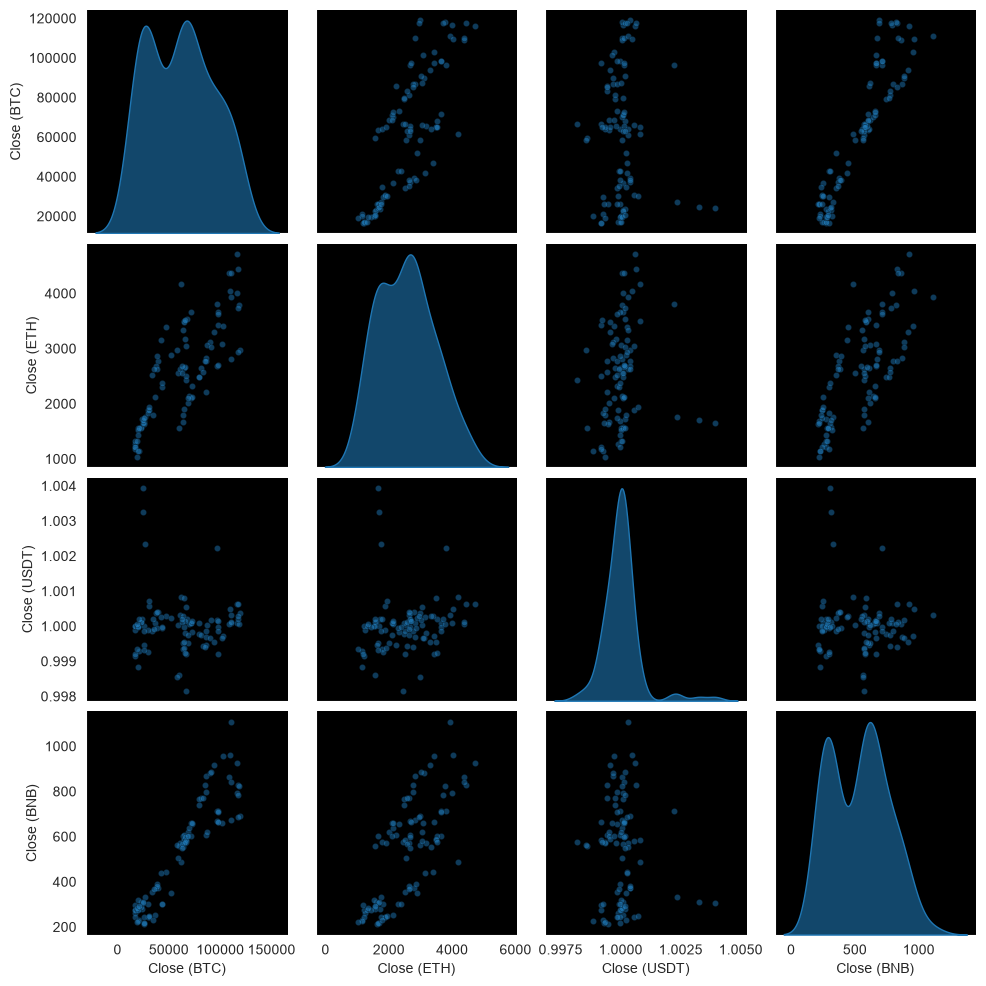

In [37]:
sns.pairplot(data.sample(n=100), vars=['Close (BTC)', 'Close (ETH)', 'Close (USDT)', 'Close (BNB)'], 
             kind='scatter', 
             diag_kind='kde', 
             plot_kws={'alpha': 0.5, 's': 20, 'edgecolor': 'k'}, 
             diag_kws={'shade': True, 'alpha': 0.6});

In [42]:
X = data.drop(columns=['Close (BTC)'])
Y = data.loc[:, 'Close (BTC)']

In [43]:
X.head()

,Volume (BTC),Close (ETH),Volume (ETH),Close (USDT),Volume (USDT),Close (BNB),Volume (BNB)
Date,,,,,,,
2021-10-08 00:00:00+00:00,34800873924,3563.759277,16222029488,1.000116,79865522045,419.102051,2678048368
2021-10-09 00:00:00+00:00,32491211414,3575.716797,12707036942,1.000046,67391135102,421.549469,1404867667
2021-10-10 00:00:00+00:00,39527792364,3425.852783,16171746693,1.001018,69927661418,405.069305,1437068558
2021-10-11 00:00:00+00:00,42637331698,3545.354004,18579189588,1.000696,75741431317,413.456207,1473121389
2021-10-12 00:00:00+00:00,41083758949,3492.573242,18109578443,1.000096,73275476508,443.867523,3142304145


In [45]:
X.tail()

,Volume (BTC),Close (ETH),Volume (ETH),Close (USDT),Volume (USDT),Close (BNB),Volume (BNB)
Date,,,,,,,
2026-10-04 00:00:00+00:00,15031650242,2726.509033,5943841130,0.999790,38186771396,795.264099,1195825218
2026-10-05 00:00:00+00:00,30242651384,2711.031494,12303844539,0.999853,71514114557,786.810486,1629945521
2026-10-06 00:00:00+00:00,25245965925,2697.516357,10986122667,0.999845,60953147088,779.615967,1273219160
2026-10-07 00:00:00+00:00,38737709051,2573.527344,20082324906,0.999445,88736239765,772.301270,1545007708
2026-10-08 00:00:00+00:00,41290637312,2418.159912,18232395776,0.999290,91534082048,725.039978,1632919680


In [46]:
Y.head()

Date
2021-10-08 00:00:00+00:00    53967.847656
2021-10-09 00:00:00+00:00    54968.222656
2021-10-10 00:00:00+00:00    54771.578125
2021-10-11 00:00:00+00:00    57484.789062
2021-10-12 00:00:00+00:00    56041.058594
Name: Close (BTC), dtype: float64

In [47]:
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.2, random_state=0)

In [48]:
print(f'X_train shape: {X_train.shape}')
print(f'X_test shape: {X_test.shape}')
print(f'y_train shape: {Y_train.shape}')
print(f'y_test shape: {Y_test.shape}')

X_train shape: (1461, 7)
X_test shape: (366, 7)
y_train shape: (1461,)
y_test shape: (366,)


In [49]:
from sklearn.feature_selection import SelectKBest

fs = SelectKBest(k=4)
X_train = fs.fit_transform(X_train, Y_train)
X_test = fs.transform(X_test)

d:\my_python\myenv\Lib\site-packages\sklearn\feature_selection\_univariate_selection.py:107: RuntimeWarning: invalid value encountered in divide
  msw = sswn / float(dfwn)


In [50]:
mask = fs.get_support()
selected_features = X.columns[mask]
print("Selected Features:", selected_features) 

Selected Features: Index(['Close (USDT)', 'Volume (USDT)', 'Close (BNB)', 'Volume (BNB)'], dtype='str')


In [51]:
X_train

array([[9.99091983e-01, 4.67948736e+10, 2.30846359e+02, 1.31003138e+09],
       [9.99087989e-01, 5.85856128e+10, 3.16760559e+02, 2.22814410e+09],
       [9.99182999e-01, 2.67240332e+10, 2.36280685e+02, 5.02420772e+08],
       ...,
       [1.00028706e+00, 1.08840158e+11, 6.30322449e+02, 1.58539132e+09],
       [1.00022101e+00, 3.62822333e+10, 3.17889923e+02, 6.63981561e+08],
       [9.99899030e-01, 2.54100280e+10, 2.16399292e+02, 5.66160608e+08]],
      shape=(1461, 4))

In [52]:
from sklearn.preprocessing import MinMaxScaler
scaler = MinMaxScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [53]:
from sklearn.datasets import make_regression
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import mean_squared_error, r2_score

----- Linear Regression -----
Mean Squared Error (MSE): 121203494.81679864
R-squared: 0.8616080987737258

----- Ridge Regression -----
Mean Squared Error (MSE): 121774603.19967899
R-squared: 0.8609559989722099

----- Lasso Regression -----
Mean Squared Error (MSE): 121159706.0405238
R-squared: 0.861658097431027

----- ElasticNet Regression -----
Mean Squared Error (MSE): 750265650.384808
R-squared: 0.14333584243207897

----- Support Vector Regression (SVR) -----
Mean Squared Error (MSE): 865173394.4914048
R-squared: 0.012132520311947448

----- Decision Tree Regression -----
Mean Squared Error (MSE): 132080006.65708986
R-squared: 0.8491891404378862

----- Random Forest Regression -----
Mean Squared Error (MSE): 72282547.87343603
R-squared: 0.9174667426809416

----- Gradient Boosting Regression -----
Mean Squared Error (MSE): 75411239.69230013
R-squared: 0.9138943571666613

----- K-Nearest Neighbors Regression -----
Mean Squared Error (MSE): 76310713.76279446
R-squared: 0.912867324679622

d:\my_python\myenv\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(


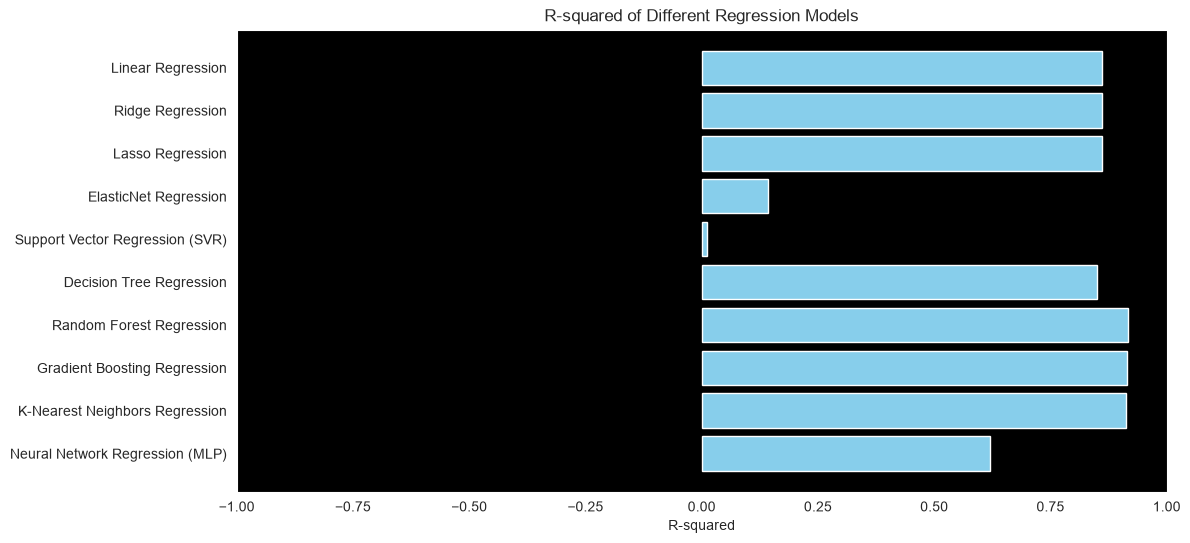

In [59]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import mean_squared_error, r2_score

# Define models
models = {
    'Linear Regression': LinearRegression(),

    'Ridge Regression': Ridge(
        alpha=1.0, solver='auto', random_state=0
    ),

    'Lasso Regression': Lasso(
        alpha=1.0, random_state=0
    ),

    'ElasticNet Regression': ElasticNet(
        alpha=1.0, l1_ratio=0.5, random_state=0
    ),

    'Support Vector Regression (SVR)': SVR(
        kernel='rbf', C=1.0, epsilon=0.1
    ),

    'Decision Tree Regression': DecisionTreeRegressor(),

    'Random Forest Regression': RandomForestRegressor(
        n_estimators=100, random_state=0
    ),

    'Gradient Boosting Regression': GradientBoostingRegressor(
        n_estimators=100, learning_rate=0.1, random_state=0
    ),

    'K-Nearest Neighbors Regression': KNeighborsRegressor(
        n_neighbors=5,
        weights='uniform',
        algorithm='auto',
        leaf_size=30,
        p=2,
        metric='minkowski',
        metric_params=None,
        n_jobs=None
    ),

    'Neural Network Regression (MLP)': MLPRegressor(
        hidden_layer_sizes=(100, 50),
        activation='relu',
        solver='adam',
        random_state=0,
        max_iter=500,
        early_stopping=True,
        validation_fraction=0.1,
        n_iter_no_change=10
    )
}

# Train and evaluate each model
results = {'Model': [], 'MSE': [], 'R-squared': []}

for name, model in models.items():
    model.fit(X_train, Y_train)

    Y_pred = model.predict(X_test)

    mse = mean_squared_error(Y_test, Y_pred)
    r2 = r2_score(Y_test, Y_pred)

    results['Model'].append(name)
    results['MSE'].append(mse)
    results['R-squared'].append(r2)

    print(f"----- {name} -----")
    print(f"Mean Squared Error (MSE): {mse}")
    print(f"R-squared: {r2}")
    print()

# Convert results to DataFrame
results_df = pd.DataFrame(results)
print(results_df)

# Plot the results
plt.figure(figsize=(12, 6))
plt.barh(results_df['Model'], results_df['R-squared'], color='skyblue')
plt.xlabel('R-squared')
plt.title('R-squared of Different Regression Models')
plt.xlim(-1, 1)
plt.gca().invert_yaxis()
plt.show()

In [60]:
import pickle
import numpy as np
from sklearn.datasets import make_regression
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error, r2_score

# Generate sample data
X, Y = make_regression(n_samples=1000, n_features=10, noise=0.1, random_state=0)


# Scale the features (optional but recommended for some algorithms)
scaler = MinMaxScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# Initialize Random Forest Regressor
model_rf = RandomForestRegressor(n_estimators=100, random_state=0)

# Train the model
model_rf.fit(X_train, Y_train)

# Save the model to a file
filename = 'random_forest_model.pkl'
pickle.dump(model_rf, open(filename, 'wb'))

# Save scaler to a file
with open('scaler.pkl', 'wb') as f:
    pickle.dump(scaler, f)

# Load the model from the file
loaded_model = pickle.load(open(filename, 'rb'))

# Predict using the loaded model
Y_pred = loaded_model.predict(X_test)

# Evaluate the loaded model
mse = mean_squared_error(Y_test, Y_pred)
r2 = r2_score(Y_test, Y_pred)

print(f"Loaded Random Forest Regression - Mean Squared Error (MSE): {mse}")
print(f"Loaded Random Forest Regression - R-squared: {r2}")


Loaded Random Forest Regression - Mean Squared Error (MSE): 72282547.87343603
Loaded Random Forest Regression - R-squared: 0.9174667426809416
